# t-SNE, den-SNE and DREAMS

*Python port of the R vignettes [t-SNE](https://gregorlueg.github.io/manifoldsR/articles/tsne.html), [densMAP and den-SNE](https://gregorlueg.github.io/manifoldsR/articles/density_preserving.html) and [DREAMS](https://gregorlueg.github.io/manifoldsR/articles/dreams.html). Original author: Gregor Lueg.*

The t-SNE family in one place. Plain
[t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html) with Barnes-Hut,
a quick-and-dirty Barnes-Hut and two flavours of
[FFT-accelerated interpolation](https://www.nature.com/articles/s41592-018-0308-4).
Then the two extensions that fix t-SNE's best known weaknesses:
[den-SNE](https://www.nature.com/articles/s41587-020-00801-7) keeps relative
density, [DREAMS](https://arxiv.org/abs/2508.13747) keeps the global
arrangement.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import openTSNE
import polars as pl
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

import manifolds_rs as mf


def scatter(
    ax: plt.Axes, emb: np.ndarray, c: np.ndarray, title: str, cmap: str = "tab10"
) -> None:
    """One embedding, coloured by `c`, without axis ticks."""
    ax.scatter(emb[:, 0], emb[:, 1], c=c, s=1, cmap=cmap, alpha=0.6)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def panels(
    embeddings: dict[str, np.ndarray], c: np.ndarray, cmap: str = "tab10"
) -> None:
    """A row of embeddings sharing one colouring."""
    fig, axes = plt.subplots(
        1, len(embeddings), figsize=(4.3 * len(embeddings), 4.3), squeeze=False
    )
    for ax, (name, emb) in zip(axes[0], embeddings.items(), strict=True):
        scatter(ax, emb, c, name, cmap)
    fig.tight_layout()

## t-SNE

t-SNE models pairwise similarities as a Gaussian in the input space and a
Student t in the embedding, then minimises the KL divergence between the
two. The heavy tails of the t are the trick: dissimilar points can sit far
apart without huge gradients, which is what fixes the crowding problem of
earlier methods. Compared to UMAP:

- **Better on continuous structure.** The loss is symmetric and driven by
  pairwise probabilities rather than graph connectivity, so it tears
  continuous manifolds apart less readily. Not immune though, especially at
  low perplexity.
- **Slower.** Naive t-SNE is `O(N^2)`. Barnes-Hut gets it to `O(N log N)`,
  the FFT versions to `O(N)` with a bigger constant.
- **Distances in the embedding mean nothing.** Cluster sizes and gaps
  between clusters
  [should not be over-interpreted](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1011288).

Perplexity is the knob: roughly the effective number of neighbours per
point. 5 to 50 is the usual range. Low values chase local structure, high
values pull in more of the global picture.

In [2]:
X_clust, y_clust = mf.datasets.clustered(25_000)
X_swiss, t_swiss = mf.datasets.swiss_roll(1_000)
X_traj, y_traj = mf.datasets.trajectory(25_000)

### Clustered data

Ten Gaussian clusters in 50 dimensions. PCA first, for a baseline.

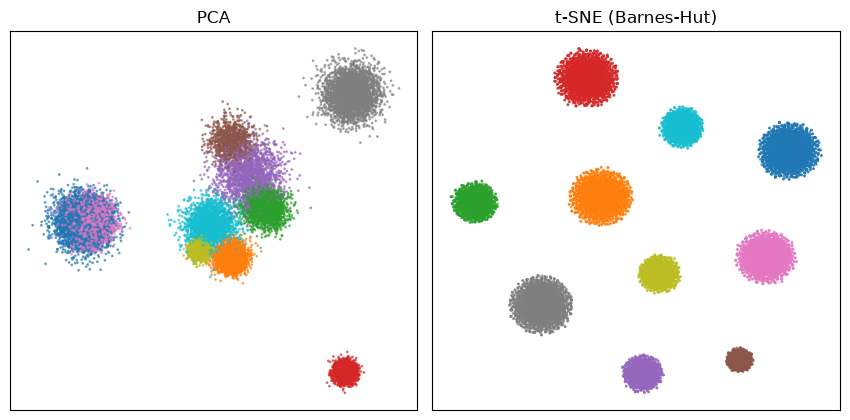

In [3]:
panels(
    {
        "PCA": PCA(2).fit_transform(X_clust),
        "t-SNE (Barnes-Hut)": mf.TSNE(perplexity=30.0).fit_transform(X_clust),
    },
    y_clust,
)

Clean separation, as expected. The gaps between the clusters and their sizes
are not something t-SNE tries to get right, so don't read them.

### Swiss roll

A 2-D sheet rolled up in 3-D, coloured by the position along the roll. We
need a higher perplexity here to give the global structure a chance, and with
1000 points an exact search costs nothing.

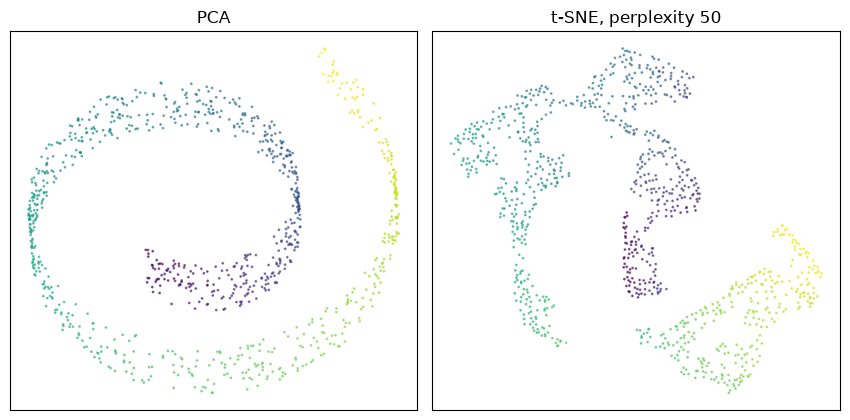

In [4]:
panels(
    {
        "PCA": PCA(2).fit_transform(X_swiss),
        "t-SNE, perplexity 50": mf.TSNE(
            perplexity=50.0, ann="exhaustive"
        ).fit_transform(X_swiss),
    },
    t_swiss,
    cmap="viridis",
)

The colour gradient along the roll survives. Not a proper unrolling though:
for that, look at PHATE.

### Trajectory

A branching trajectory in 50 dimensions, coloured by branch. The points are
shuffled before plotting so the later branches don't hide the earlier ones.

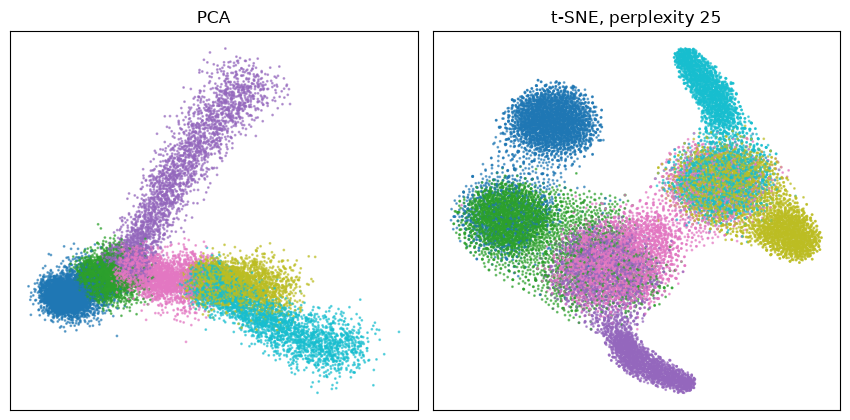

In [5]:
order = np.random.default_rng(42).permutation(len(y_traj))
panels(
    {
        "PCA": PCA(2).fit_transform(X_traj)[order],
        "t-SNE, perplexity 25": mf.TSNE(perplexity=25.0).fit_transform(X_traj)[order],
    },
    y_traj[order],
)

t-SNE gets the branches out of the PCA blob, but without knowing the
differentiation path you would struggle to read the order off this plot.

## Pre-computed kNN graphs

Sweeping perplexity or epochs? Compute the graph once. t-SNE wants
`3 * perplexity` neighbours, so the widest perplexity you plan to try sets
`k`. A narrower graph is an error, a wider one is cut down.

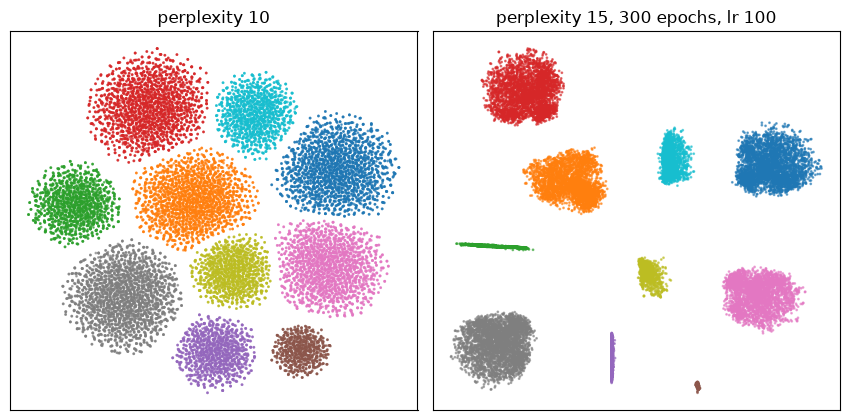

In [6]:
idx, dist = mf.knn_graph(X_clust, k=45, ann="ivf")

panels(
    {
        "perplexity 10": mf.TSNE(perplexity=10.0).fit_transform(
            X_clust, knn_indices=idx, knn_distances=dist
        ),
        "perplexity 15, 300 epochs, lr 100": mf.TSNE(
            perplexity=15.0, n_epochs=300, learning_rate=100.0
        ).fit_transform(X_clust, knn_indices=idx, knn_distances=dist),
    },
    y_clust,
)

The second one stops early with a small learning rate, which is how you get
the half-cooked look on purpose.

## The repulsion approximations

The attractive forces only run over the kNN graph and are cheap. The
repulsion runs over all pairs and is where the time goes. Four ways to
approximate it, picked with `approx`:

- `"barnes_hut"` (default, alias `"bh"`): a quadtree, `O(N log N)`.
- `"bh_qd"` (alias `"qd"`): the quick-and-dirty Barnes-Hut from
  [qdtsne](https://github.com/libscran/qdtsne). The tree depth is capped at
  `TsneOptim(max_depth=...)` (default 7), and repulsion is computed once per
  leaf from its centre of mass instead of once per point. A bit less
  precise, a lot faster. qdtsne recommends depths of 7 to 10.
- `"fft"`: FIt-SNE. Charges are spread onto an interpolation grid and the
  repulsion comes out of an FFT convolution. `O(N)`, with a constant that
  only pays off from roughly 100k points.
- `"fft_3k"`: the three-kernel variant. Put a unit charge on the grid and
  convolve it with three kernels (`q`, `q^2 dx` and `q^2 dy`), which hands
  you the normalisation and the forces directly. One forward and three
  inverse transforms per epoch instead of four and four.

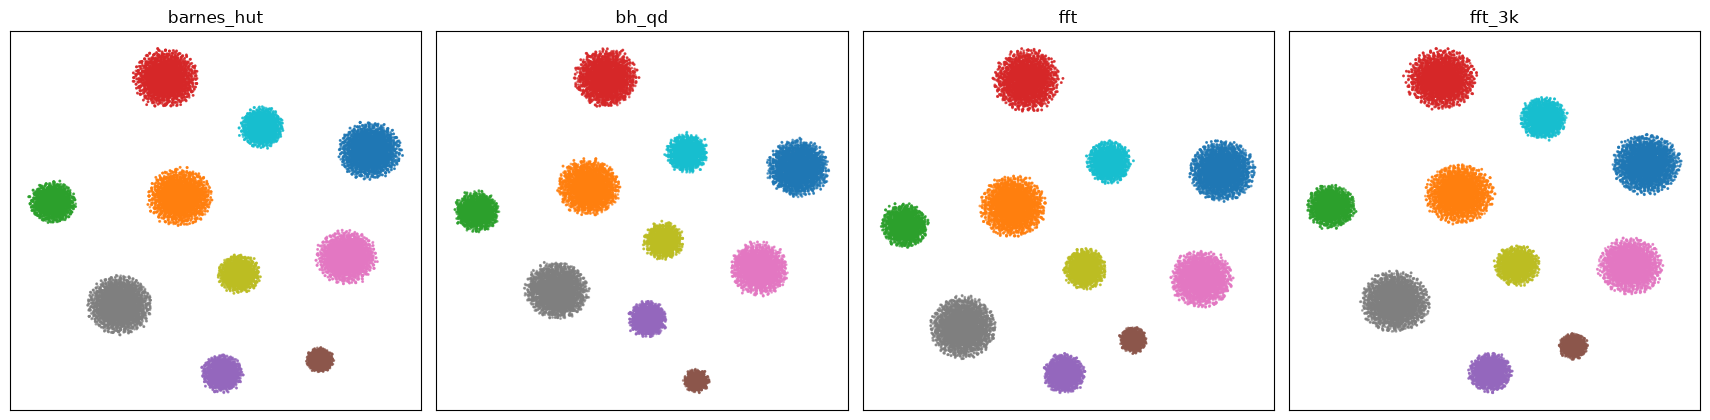

In [7]:
approx = {
    name: mf.TSNE(perplexity=30.0, approx=name).fit_transform(X_clust)
    for name in ("barnes_hut", "bh_qd", "fft", "fft_3k")
}
panels(approx, y_clust)

Same picture four times. On large data you may see the clusters stop being
islands and relax into a gapless disc, tiled into Voronoi-like cells. That is
not a convergence failure. The main phase runs at an exaggeration of 1, and
at high point density the equilibrium of that setting is space filling. Set
`TsneOptim(late_exag_factor=...)` to 2 to 4 and the gaps come back.

## den-SNE: keeping density

t-SNE carries the same warning as UMAP: cluster sizes in the embedding mean
nothing. A blob twice as wide as its neighbour might be ten times tighter in
the input. Neither loss has a term that cares how spread out a neighbourhood
was to begin with.

den-SNE adds one:

$$-\lambda \cdot \mathrm{Corr}(\log R_o, \log R_e)$$

$R_o$ is a local radius in the input, a graph-weighted average squared
distance to a point's neighbours, and $R_e$ the matching radius in the
embedding. Maximise their correlation and a tight cluster stays tight, a
diffuse one stays diffuse. The term only switches on over the last
`DensParams(frac=...)` of the epochs (default 30%), so it corrects a settled
layout instead of fighting the initialisation. `lambda_` weighs it, and `0`
gives you plain t-SNE back.

To see any of this we need to measure local density before and after. A
proxy for $R_o$: the log of the mean squared distance to the 15 nearest
neighbours. The cluster generator draws a different spread per cluster, so
there is real density variation to keep.

In [8]:
def local_radii(x: np.ndarray, k: int = 15) -> np.ndarray:
    """Log mean squared distance to the `k` nearest neighbours, per point."""
    _, d = mf.knn_graph(x, k=k, ann="kmknn")
    return np.log((d.astype(np.float64) ** 2).mean(axis=1) + 1e-8)


X_dens, y_dens = mf.datasets.clustered(10_000, n_clusters=8)
radii = local_radii(X_dens)

pl.DataFrame({"cluster": y_dens, "log_radius": radii}).group_by("cluster").agg(
    pl.col("log_radius").mean().round(2)
).sort("cluster")

cluster,log_radius
i64,f64
0,5.51
1,4.23
2,4.93
3,3.51
4,5.88
5,5.07
6,5.11
7,5.39


Now t-SNE against den-SNE, both coloured by the *input* radius. If the
embedding keeps density, the colour should track how big the blobs look.

method,rho
str,f64
"""t-SNE""",0.035
"""den-SNE""",0.542


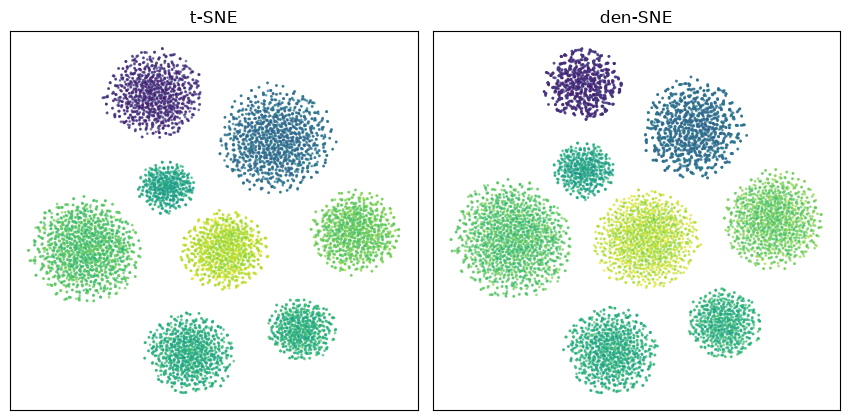

In [9]:
dens = {
    "t-SNE": mf.TSNE(perplexity=15.0).fit_transform(X_dens),
    "den-SNE": mf.DensNE(perplexity=15.0).fit_transform(X_dens),
}
panels(dens, radii, cmap="viridis")

pl.DataFrame(
    {
        "method": list(dens),
        "rho": [spearmanr(radii, local_radii(e)).statistic for e in dens.values()],
    }
).with_columns(pl.col("rho").round(3))

`rho` is the Spearman correlation between input and embedding radii. Turn
`lambda_` up if you want more of it; the UMAP vignette sweeps the same knob
for densMAP. den-SNE inherits every t-SNE constraint: two dimensions only, a
pre-computed graph needs more than `perplexity` neighbours, and every
`approx` works.

## DREAMS: keeping the global arrangement

t-SNE throws away where the clusters sit relative to each other. DREAMS gets
it back with a pull towards a reference layout. Every epoch it scales the
usual update by `1 - lambda` and adds

$$-\eta \lambda^2 \frac{2}{n} (y - \alpha y_e)$$

$y_e$ is the centred reference, $\alpha = \|Y\|_F / \|Y_e\|_F$ rescales it to
the current size of the embedding, and $\eta$ is the automatic openTSNE
learning rate. The optimisation starts from the reference too, so `init` is
ignored. `lambda_` lives in `[0, 1]`: `0` is t-SNE started from the
reference, `1` returns the reference. The default `0.15` is the paper's. The
extra term is `O(n)` per epoch, so DREAMS costs what t-SNE costs, and every
`approx` works.

Two numbers per embedding. Global: the Spearman correlation between
subcluster centroid distances in the input and in the embedding. Local: the
fraction of each point's 15 nearest neighbours that survive.

In [10]:
def global_preservation(x: np.ndarray, emb: np.ndarray, groups: np.ndarray) -> float:
    """Spearman correlation of group centroid distances, input vs embedding."""
    ids = np.unique(groups)
    cx = np.stack([x[groups == g].mean(axis=0) for g in ids])
    ce = np.stack([emb[groups == g].mean(axis=0) for g in ids])
    return float(spearmanr(pdist(cx), pdist(ce)).statistic)


def knn_preservation(x: np.ndarray, emb: np.ndarray, k: int = 15) -> float:
    """Mean fraction of each point's `k` exact neighbours kept in the embedding."""
    a, _ = mf.knn_graph(x, k=k, ann="exhaustive")
    b, _ = mf.knn_graph(emb, k=k, ann="exhaustive")
    return sum(len(set(i) & set(j)) for i, j in zip(a, b, strict=True)) / a.size


def scores(x: np.ndarray, embs: dict[str, np.ndarray], groups: np.ndarray):
    """Global and local preservation per embedding, as a table."""
    return pl.DataFrame(
        {
            "method": list(embs),
            "global": [global_preservation(x, e, groups) for e in embs.values()],
            "local": [knn_preservation(x, e) for e in embs.values()],
        }
    ).with_columns(pl.col("global", "local").round(3))

The hierarchical generator gives us 16 subclusters in 4 supergroups, in 50
dimensions. Subclusters within a supergroup are close, supergroups are far
apart. Exactly the structure t-SNE throws away.

method,global,local
str,f64,f64
"""PCA""",0.927,0.067
"""t-SNE""",0.505,0.231
"""DREAMS""",0.848,0.19


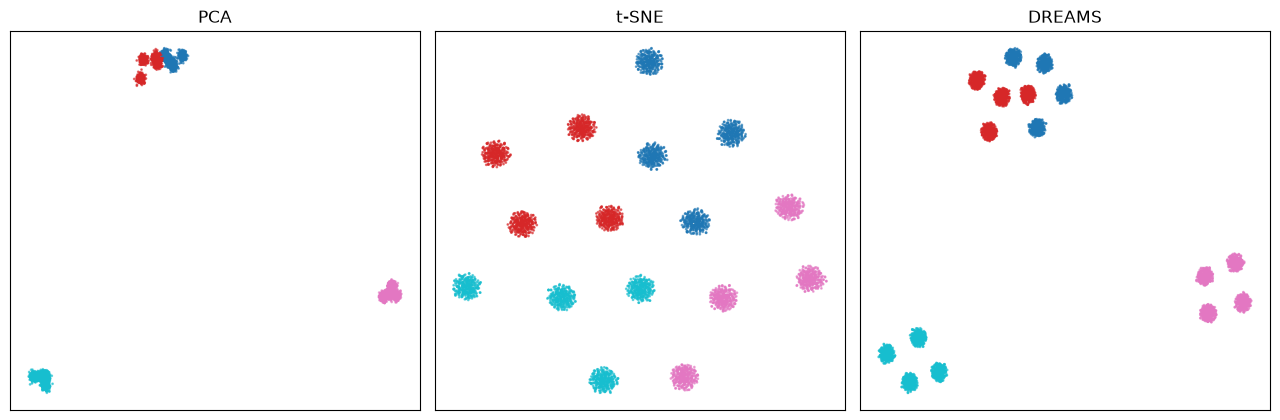

In [11]:
X_hier, supergroup, subgroup = mf.datasets.hierarchical(5_000, n_subclusters=4)

hier = {
    "PCA": PCA(2).fit_transform(X_hier),
    "t-SNE": mf.TSNE().fit_transform(X_hier),
    "DREAMS": mf.DREAMS().fit_transform(X_hier),
}
panels(hier, supergroup)
scores(X_hier, hier, subgroup)

Coloured by supergroup. PCA puts the supergroups in the right places and
smears the subclusters inside them. t-SNE separates all 16 subclusters and
scatters them over the plane with no regard for their supergroup. DREAMS
keeps the subclusters apart and the supergroups together. PCA's local score
is dismal: two dimensions out of fifty is not enough to keep anyone's
neighbours.

### Tuning lambda

A sweep from t-SNE to PCA.

method,global,local
str,f64,f64
"""lambda = 0.0""",0.471,0.227
"""lambda = 0.05""",0.781,0.222
"""lambda = 0.15""",0.848,0.19
"""lambda = 0.5""",0.912,0.137
"""lambda = 1.0""",0.927,0.067


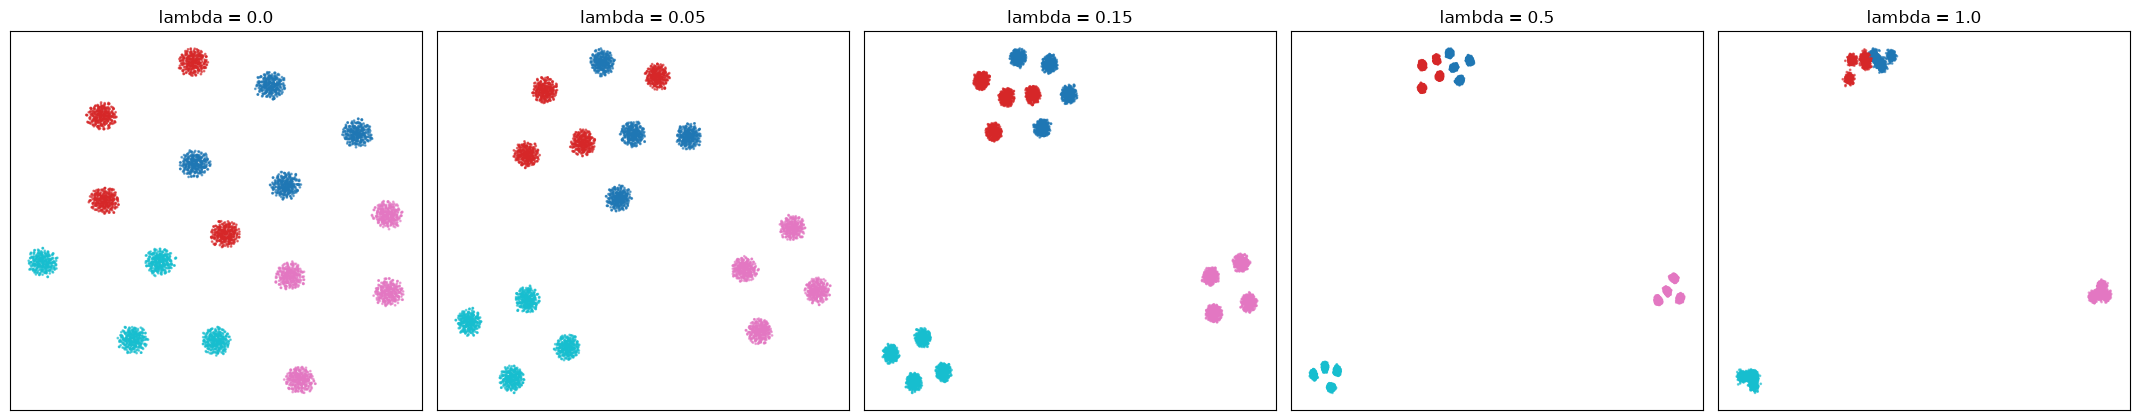

In [12]:
sweep = {
    f"lambda = {lam}": mf.DREAMS(lambda_=lam).fit_transform(X_hier)
    for lam in (0.0, 0.05, 0.15, 0.5, 1.0)
}
panels(sweep, supergroup)
scores(X_hier, sweep, subgroup)

Even `0.05` buys most of the global structure back. The local score holds up
to the default and then drops off fast. Past `0.5` you are looking at a
slightly sharpened PCA, and at `1` nothing moves at all: the reference at its
initialisation scale. Start at the default; go lower if the subclusters
start to touch.

### Bring your own reference

PCA is a fine reference when the global structure is linear-ish. When it is
not, pass something better via `reference` in `fit`: any `(n_samples, 2)`
array. On a branching trajectory PHATE is the obvious pick.

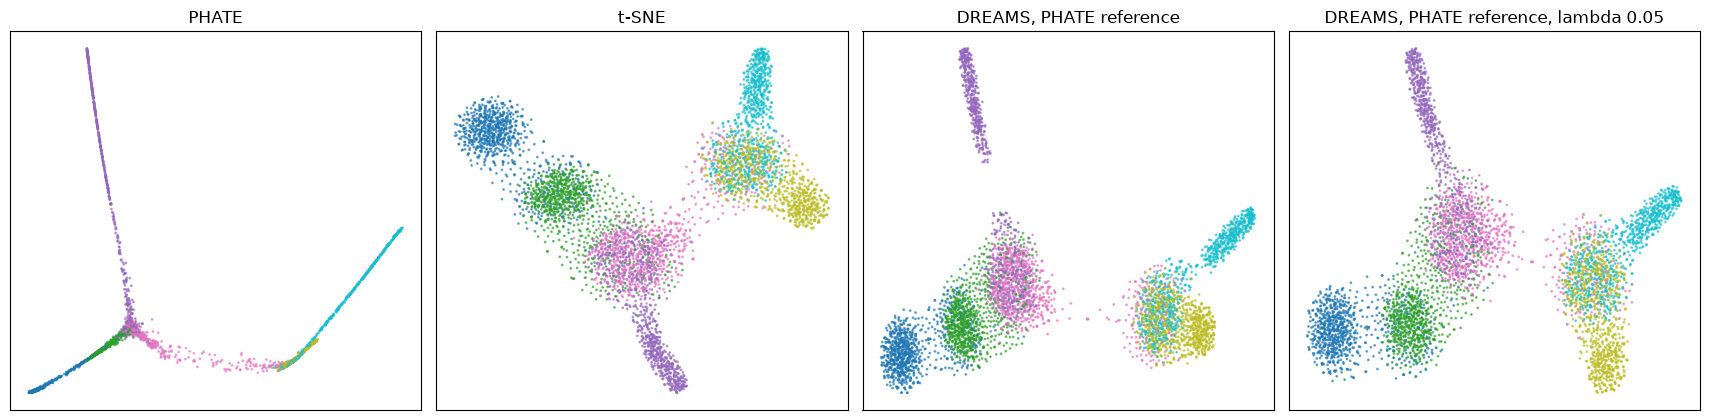

In [13]:
X_t5, y_t5 = mf.datasets.trajectory(5_000)
phate_ref = mf.PHATE(k=15).fit_transform(X_t5)

order = np.random.default_rng(42).permutation(len(y_t5))
panels(
    {
        "PHATE": phate_ref[order],
        "t-SNE": mf.TSNE().fit_transform(X_t5)[order],
        "DREAMS, PHATE reference": mf.DREAMS().fit_transform(X_t5, reference=phate_ref)[
            order
        ],
        "DREAMS, PHATE reference, lambda 0.05": mf.DREAMS(lambda_=0.05).fit_transform(
            X_t5, reference=phate_ref
        )[order],
    },
    y_t5[order],
)

The branch order along the stem follows PHATE. Long PHATE tips can tear off
into islands at the default `lambda_`: that is DREAMS itself, the authors'
openTSNE fork does the same. A lower `lambda_` keeps them in one piece, so on
long trajectories go below the default.

## Benchmarks

Against [openTSNE](https://github.com/pavlin-policar/openTSNE), the fastest
t-SNE in Python, on all cores. One run each, wall time in seconds. Mind that
the epochs differ: openTSNE runs 250 early exaggeration plus 500 iterations,
we run 1000 in total.

In [14]:
def timed(fn) -> float:
    """Wall time of one call, in seconds."""
    start = time.perf_counter()
    fn()
    return time.perf_counter() - start


def bench(x: np.ndarray, ours: list[str], open_tsne: list[str]) -> pl.DataFrame:
    """Wall time of our approximations and openTSNE's on `x`."""
    rows = [
        {
            "method": f"manifolds-rs {a}",
            "seconds": timed(
                lambda a=a: mf.TSNE(perplexity=30.0, approx=a).fit_transform(x)
            ),
        }
        for a in ours
    ]
    rows += [
        {
            "method": f"openTSNE {m}",
            "seconds": timed(
                lambda m=m: openTSNE.TSNE(
                    perplexity=30,
                    negative_gradient_method=m,
                    n_jobs=-1,
                    random_state=42,
                ).fit(x)
            ),
        }
        for m in open_tsne
    ]
    return pl.DataFrame(rows).with_columns(pl.col("seconds").round(2))


bench(mf.datasets.clustered(5_000)[0], ["barnes_hut", "bh_qd"], ["bh"])

method,seconds
str,f64
"""manifolds-rs barnes_hut""",1.95
"""manifolds-rs bh_qd""",1.12
"""openTSNE bh""",20.49


And at 75k points, where the FFT versions come into their own.

In [15]:
bench(
    mf.datasets.clustered(75_000)[0],
    ["barnes_hut", "bh_qd", "fft", "fft_3k"],
    ["fft"],
)

method,seconds
str,f64
"""manifolds-rs barnes_hut""",30.09
"""manifolds-rs bh_qd""",6.04
"""manifolds-rs fft""",8.5
"""manifolds-rs fft_3k""",7.41
"""openTSNE fft""",60.07


On 5k points Barnes-Hut is close to an order of magnitude ahead of openTSNE.
The neighbour search, the affinities and the optimisation all run in Rust,
with no round trips through Python. At 75k plain Barnes-Hut starts to hurt,
and the quick-and-dirty tree keeps up with both FFT versions. If you like
t-SNE but thought it was too slow, this is for you.